## 1. Before You Begin

**What do we actually check on a model card before we build with the model?** In this notebook two hosts, Harper and Grant, walk through the real model cards of three models: MAI-Voice-2.1, MAI-Transcribe-2, and MAI-Image-2.6-Flash. They are the same three models that make the episode, so each claim the hosts make is one we can check. Along the way we build a small podcast player, and we find and fix a real transcription problem.

This is the first notebook of the [Foundry podcast studio](README.md) scenario. It runs on its own.

| Detail | Value |
|---|---|
| Models | [MAI-Voice-2.1](https://ai.azure.com/catalog/models/MAI-Voice-2.1), [MAI-Transcribe-2](https://ai.azure.com/catalog/models/MAI-Transcribe-2), [MAI-Image-2.6-Flash](https://ai.azure.com/catalog/models/MAI-Image-2.6-Flash), [MAI-Image-2.6](https://ai.azure.com/catalog/models/MAI-Image-2.6), and [Microsoft-Decision-1](../../microsoft/microsoft-decision-1/README.md) as the checker |
| Pricing | Voice \$22 per 1M characters, Transcribe \$0.10 per hour (early-bird), images per token. Rates are from the model cards on 2026-10-12, so check them again. Section 13 shows what this run costs |
| Background | [Model cards primer](../../../docs/primers/model-cards.md) |

**Prerequisites**

1. A Microsoft Foundry project with the deployments listed in the [scenario README](README.md#before-you-begin): `decision-1`, `slide-art`, and `cover-art`. MAI-Voice-2.1 and MAI-Transcribe-2 need no deployment. See [models/quickstart/](../../quickstart/README.md) for first-time setup.
2. The environment variables listed in section 2.
3. The Python packages in the next cell.

> Several of these models are previews, and the image card says so. A run sends about 31 short speech requests, 10 transcription requests, 6 image requests, and a few dozen small checks.

## 2. Verify your environment

The cell below checks the variables this notebook needs and builds the endpoints it calls. It makes no paid request.

In [1]:
%pip install requests python-dotenv pandas matplotlib pillow azure-cognitiveservices-speech azure-ai-transcription --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
from dotenv import load_dotenv
load_dotenv()

import os
from urllib.parse import urlparse

# Your .env file needs these variables:
#   MICROSOFT_FOUNDRY_ENDPOINT=https://<resource>.services.ai.azure.com/api/projects/<project>
#   MICROSOFT_FOUNDRY_API_KEY=<your key>
#   AZURE_DECISION_1_DEPLOYMENT=<Microsoft-Decision-1 deployment name>
#   AZURE_SLIDE_ART_DEPLOYMENT=<MAI-Image-2.6-Flash deployment name>
#   AZURE_COVER_ART_DEPLOYMENT=<MAI-Image-2.6 deployment name>
REQUIRED = {
    "MICROSOFT_FOUNDRY_ENDPOINT": "Foundry project endpoint",
    "MICROSOFT_FOUNDRY_API_KEY": "Foundry API key",
    "AZURE_DECISION_1_DEPLOYMENT": "Microsoft-Decision-1 deployment name",
    "AZURE_SLIDE_ART_DEPLOYMENT": "MAI-Image-2.6-Flash deployment name",
    "AZURE_COVER_ART_DEPLOYMENT": "MAI-Image-2.6 deployment name",
}
missing = [name for name in REQUIRED if not os.environ.get(name)]
if missing:
    raise EnvironmentError(
        f"Set these in your .env file before continuing: {missing}. "
        "See models/multi-model-scenarios/foundry-podcast-studio/README.md for the deploy commands."
    )

parsed = urlparse(os.environ["MICROSOFT_FOUNDRY_ENDPOINT"])
BASE = f"{parsed.scheme}://{parsed.netloc}"
API_KEY = os.environ["MICROSOFT_FOUNDRY_API_KEY"]
DECISION_DEPLOYMENT = os.environ["AZURE_DECISION_1_DEPLOYMENT"]
SLIDE_ART_DEPLOYMENT = os.environ["AZURE_SLIDE_ART_DEPLOYMENT"]
COVER_ART_DEPLOYMENT = os.environ["AZURE_COVER_ART_DEPLOYMENT"]
# Speech takes the same key. The cognitiveservices host is the usual Speech endpoint form.
SPEECH_ENDPOINT = os.environ.get("AZURE_SPEECH_ENDPOINT") or (
    "https://" + parsed.netloc.replace(".services.ai.azure.com", ".cognitiveservices.azure.com") + "/"
)

print(f"Foundry host     : {parsed.netloc}")
print(f"Decision-1       : {DECISION_DEPLOYMENT}")
print(f"Slide art (Flash): {SLIDE_ART_DEPLOYMENT}")
print(f"Cover art (2.6)  : {COVER_ART_DEPLOYMENT}")
print("Environment check passed.")

Foundry host     : foundry-rg-model-releases-16629.services.ai.azure.com
Decision-1       : Decision-1
Slide art (Flash): slide-art
Cover art (2.6)  : cover-art
Environment check passed.


## 3. Frame the question

A model card is the page that says what a model is for, what it costs, and where it stops. Reading one takes a few minutes, and skipping it can cost days. So what should we look for?

In this notebook we answer that with an episode. Each of the three cards teaches one question:

| Card | The question |
|---|---|
| MAI-Voice-2.1 | What are the **limits and access rules** before we generate speech? |
| MAI-Transcribe-2 | What can we **ask it to return**, and what does it cost? |
| MAI-Image-2.6-Flash | What does the card **leave out**? |

The result we're looking for is a player we can open, where every claim a host makes shows the card line it came from. Before we pay for any speech, a checker model reads each claim against its card line, so the episode can't say anything its cards don't.

## 4. Read the three cards

We start with the cards, because the hosts can only be as accurate as what they read. The file `assets/card-excerpts.json` holds short quotations from each card, and every excerpt has an id such as `voice.v1`. The script cites those ids.

Cards change, so we also check each excerpt against the live card. An early-bird price or a lifecycle label is the kind of line that moves.

In [3]:
import base64
import concurrent.futures
import difflib
import hashlib
import html
import io
import json
import re
import shutil
import time
import wave
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
from IPython.display import HTML, Audio, display
from PIL import Image

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 90)

ASSETS = Path("assets")
OUT_DIR = Path("output")
for sub in ("audio", "images", "episode"):
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)

MAX_WORKERS = 4
DECISION_URL = f"{BASE}/providers/microsoft/v1/systemone"


def decide(state, questions, retries=6):
    """POST one Microsoft-Decision-1 request and return the parsed JSON response."""
    body = {"model": DECISION_DEPLOYMENT, "state": state, "questions": questions}
    for attempt in range(retries):
        response = requests.post(DECISION_URL, headers={"api-key": API_KEY, "Content-Type": "application/json"}, json=body, timeout=60)
        if response.status_code == 429:   # rate limited: wait, then try again
            time.sleep(float(response.headers.get("Retry-After", 0)) or 1.5 * 2 ** min(attempt, 4))
            continue
        if not response.ok:
            raise requests.HTTPError(f"{response.status_code} {response.reason}: {response.text}", response=response)
        return response.json()
    raise RuntimeError("Still rate limited after several retries. Lower MAX_WORKERS or raise the deployment capacity.")


def run_parallel(function, items, workers=MAX_WORKERS):
    """Apply function to each item in parallel and return the results in input order."""
    with concurrent.futures.ThreadPoolExecutor(max_workers=workers) as executor:
        return list(executor.map(function, items))

In [4]:
CARDS = json.loads((ASSETS / "card-excerpts.json").read_text(encoding="utf-8"))


def cite_info(cite):
    """Look up one cited excerpt, such as voice.v1, with its card, link, and place on the card."""
    card_key, excerpt_id = cite.split(".")
    card = CARDS["cards"][card_key]
    return {"card": card["name"], "url": card["url"], "text": card["excerpts"][excerpt_id], "context": card["excerpt_context"][excerpt_id]}


excerpt_table = pd.DataFrame([
    {"cite": f"{key}.{excerpt_id}", "card": card["name"], "where on the card": card["excerpt_context"][excerpt_id], "excerpt": text.replace("\n", " / ")}
    for key, card in CARDS["cards"].items()
    for excerpt_id, text in card["excerpts"].items()
])
print(f"Excerpts read from the cards on {CARDS['retrieved']}")
excerpt_table

Excerpts read from the cards on 2026-10-12


,cite,card,where on the card,excerpt
0,voice.v1,MAI-Voice-2.1,"Technical specs, Context length","Up to ~45 secs per generation, with longer outputs supported via chunking."
1,voice.v2,MAI-Voice-2.1,"Key capabilities, voice cloning",Access requires Microsoft approval and guardrails are in place to avoid misuse.
2,voice.v3,MAI-Voice-2.1,Pricing,$22 per 1M characters.
3,voice.v4,MAI-Voice-2.1,Key capabilities,Multi-speaker support for dialogue and conversational scenarios.
4,voice.v5,MAI-Voice-2.1,"Responsible AI considerations, Known limitations","Synthetic voices can be misused for impersonation, misinformation, or deceptive content."
5,voice.v6,MAI-Voice-2.1,"Key capabilities, voice cloning",instant Voice Cloning: provide a short audio clip (5-60 seconds) and the model clones ...
6,transcribe.t1,MAI-Transcribe-2,Key capabilities,"Word-level timestamps: precise timing for every word, enabling alignment, search, and ..."
7,transcribe.t2,MAI-Transcribe-2,Key capabilities,"Keyword biasing to handle domain specific terminology, abbreviations or disambiguating..."
8,transcribe.t3,MAI-Transcribe-2,"Key capabilities, transcription style","`clean` removes disfluencies for readable captions, notes, and published transcripts."
9,transcribe.t4,MAI-Transcribe-2,Pricing,Early-bird pricing of $0.10 per hour of audio.


In [5]:
def normalize(text):
    """The catalog page embeds each card as escaped text, so unescape it before comparing."""
    text = text.replace("\\\\n", " ").replace("\\n", " ").replace("\\u003c", "<").replace("\\u003e", ">").replace('\\"', '"')
    text = html.unescape(re.sub(r"<[^>]+>", " ", text))
    text = text.replace("\u2011", "-").replace("\u2013", "-").replace("\u2019", "'").replace("**", "").replace("`", "")
    return re.sub(r"\s+", " ", text).lower()


def check_cards_live():
    """Fetch each live card and report whether every excerpt is still on it."""
    rows = []
    for key, card in CARDS["cards"].items():
        try:
            page = normalize(requests.get(card["url"], headers={"User-Agent": "Mozilla/5.0"}, timeout=60).text)
        except requests.RequestException as error:
            print(f"Could not fetch the {card['name']} card: {error}")
            continue
        for excerpt_id, text in card["excerpts"].items():
            rows.append({"cite": f"{key}.{excerpt_id}", "card": card["name"], "still on the live card": normalize(text) in page})
    return pd.DataFrame(rows)


live = check_cards_live()
print(f"{int(live['still on the live card'].sum())} of {len(live)} excerpts are on the live cards right now")
live[~live["still on the live card"]]

16 of 16 excerpts are on the live cards right now


,cite,card,still on the live card


Every excerpt should still be on its card. If one isn't, the card has changed since the excerpts were saved. Read the live card, update `card-excerpts.json`, and rerun the notebook, so the episode says what the card says today.

## 5. Read the script as data

The episode script is data too: `assets/episode-script.json`. Each line has a host, an optional speaking style, and the excerpts it cites. A line with no citation is conversation, such as a greeting or advice.

Counting characters now tells us what the speech will cost before we synthesize anything, because the Voice card prices by character.

In [6]:
EPISODE = json.loads((ASSETS / "episode-script.json").read_text(encoding="utf-8"))
HOSTS = EPISODE["hosts"]
LINES = [{**line, "segment": segment["id"]} for segment in EPISODE["segments"] for line in segment["lines"]]
VOICE_PRICE_PER_MILLION_CHARS = 22.0   # the Voice card's price line, read on 2026-10-12

overview = pd.DataFrame([
    {
        "segment": segment["title"],
        "lines": len(segment["lines"]),
        "words": sum(len(line["text"].split()) for line in segment["lines"]),
        "characters": sum(len(line["text"]) for line in segment["lines"]),
        "cited lines": sum(1 for line in segment["lines"] if line["cites"]),
    }
    for segment in EPISODE["segments"]
])
total_chars = int(overview.characters.sum())
print(f"{EPISODE['title']}: {len(LINES)} lines, {int(overview.words.sum())} words, {total_chars:,} characters")
print(f"Voice cost at ${VOICE_PRICE_PER_MILLION_CHARS:.0f} per 1M characters: about ${total_chars * VOICE_PRICE_PER_MILLION_CHARS / 1_000_000:.3f}")
overview

Three cards, three questions: 31 lines, 535 words, 3,052 characters
Voice cost at $22 per 1M characters: about $0.067


,segment,lines,words,characters,cited lines
0,Why read a card,4,76,440,0
1,The voice card: limits and access,7,148,846,4
2,The transcription card: what we can ask for,9,113,670,5
3,The image card: what the card leaves out,7,126,705,5
4,What we check before we build,4,72,391,0


## 6. Check the claims before we pay for speech

Cheap checks go before expensive steps. We ask Microsoft-Decision-1 two questions, and neither writes anything:

- For **cited** lines: does the host line stay within the card excerpts it cites? The answer is a choice, `supported`, `contradicted`, or `cannot_tell`.
- For **uncited** lines: does the line state a specific fact about a model? A host shouldn't slip a price or a limit into a line that has no citation.

In [7]:
GROUNDING = {
    "supported": "Every statement the host makes about the model is in the card excerpts",
    "contradicted": "A statement about the model conflicts with the excerpts, such as a different number or a reversed claim",
    "cannot_tell": "The host states a fact about the model that the excerpts do not mention",
}


def check_cited(text, cites):
    """Ask Microsoft-Decision-1 whether a host line stays within the card excerpts it cites."""
    state = {"card_excerpts": [cite_info(cite)["text"] for cite in cites], "host_line": text}
    questions = {"grounding": {"type": "choice", "instructions": "Does the host line stay within what the card excerpts say about the model?", "criteria": GROUNDING}}
    answer = decide(state, questions)["answers"]["grounding"]
    return answer["choice"], answer["confidence"]


cited = [line for line in LINES if line["cites"]]
results = run_parallel(lambda line: check_cited(line["text"], line["cites"]), cited)
gate = pd.DataFrame([
    {"line": line["id"], "cites": ", ".join(line["cites"]), "verdict": choice, "confidence": round(conf, 2), "text": line["text"][:70]}
    for line, (choice, conf) in zip(cited, results)
])
print(f"{(gate.verdict == 'supported').sum()} of {len(gate)} cited lines are supported by their excerpts")
gate

14 of 14 cited lines are supported by their excerpts


,line,cites,verdict,confidence,text
0,s1l1,voice.v1,supported,0.93,The first thing I look for is limits. The Voice card says each generat
1,s1l3,voice.v3,supported,0.85,"The card lists the price as $22 per 1M characters, so we can count our"
2,s1l4,"voice.v6, voice.v2",supported,0.99,And a caution. The card describes instant voice cloning from a short a
3,s1l6,voice.v5,supported,1.00,One more line I underline: synthetic voices can be misused for imperso
4,s2l2,transcribe.t1,supported,1.00,"Word-level timestamps, according to the card, give precise timing for"
5,s2l4,transcribe.t2,supported,0.98,It also supports keyword biasing for domain-specific terms.
6,s2l6,transcribe.t3,supported,0.99,And the card describes a clean style that removes disfluencies for rea
7,s2l7,transcribe.t4,supported,0.98,"Watch the price line, though. It says early-bird pricing of $0.10 per"
8,s2l9,transcribe.t5,supported,0.96,"The input limits are practical too: WAV, MP3, or FLAC, up to 300 MB or"
9,s3l1,image.i1,supported,0.87,"Third card, MAI-Image-2.6-Flash. Here the price line doesn't give a nu"


Every cited line should come back `supported`. While we were writing this script the same check flagged two lines as `cannot_tell`. One said "Voice cloning is gated" when the excerpt it cited never mentioned cloning. The other added that the clean style "suits published captions better than a verbatim transcript", which no excerpt says. Both lines sounded right, and both went a little past the card. We reworded them, and one now cites a second excerpt, so the episode says only what its cards say.

The check reads only what we give it, so a thin excerpt makes a thin check. That's why the excerpts are exact quotations.

### 6.1 Does the gate catch a bad claim?

A gate that never fails proves nothing. We tamper with the price line, changing \$22 to \$2, and ask again.

In [8]:
# A deliberately wrong version of the price line, to see the gate catch a bad claim.
price_line = next(line for line in LINES if line["id"] == "s1l3")
wrong_text = price_line["text"].replace("$22", "$2")

choice, conf = check_cited(wrong_text, price_line["cites"])
print("Original :", price_line["text"])
print("Tampered :", wrong_text)
print(f"\nVerdict on the tampered line: {choice} (confidence {conf:.2f})")

Original : The card lists the price as $22 per 1M characters, so we can count our characters and know the cost before we synthesize anything.
Tampered : The card lists the price as $2 per 1M characters, so we can count our characters and know the cost before we synthesize anything.

Verdict on the tampered line: contradicted (confidence 0.99)


In [9]:
FACT_CHECK = {
    "type": "noul",
    "instructions": "Does this line state a specific fact about a model's price, limits, access, or lifecycle?",
    "criteria": {
        "true": "Names a number, limit, price, date, approval requirement, or status for a model",
        "false": "Conversation, opinion, advice, or a description of what we do in this episode",
    },
}

uncited = [line for line in LINES if not line["cites"]]
probabilities = run_parallel(lambda line: decide({"host_line": line["text"]}, {"fact": FACT_CHECK})["answers"]["fact"]["noul"], uncited)
uncited_table = pd.DataFrame({"line": [line["id"] for line in uncited], "p_states_a_fact": [round(p, 2) for p in probabilities], "text": [line["text"][:78] for line in uncited]})
print(f"{(uncited_table.p_states_a_fact >= 0.5).sum()} of {len(uncited_table)} uncited lines look like they state a fact")

# The same check on a greeting that slips in a price.
slipped = "Thanks for listening. The voice costs about five dollars an hour."
slipped_p = decide({"host_line": slipped}, {"fact": FACT_CHECK})["answers"]["fact"]["noul"]
print(f"A greeting that slips in a price scores {slipped_p:.2f}, against {uncited_table.p_states_a_fact.max():.2f} for the highest real line.")
uncited_table.sort_values("p_states_a_fact", ascending=False).head(5)

0 of 17 uncited lines look like they state a fact


A greeting that slips in a price scores 0.99, against 0.07 for the highest real line.


,line,p_states_a_fact,text
4,s1l2,0.07,So we didn't hand it one long script. We split every host turn into short line
5,s1l5,0.04,"So we only use the prebuilt voices, Harper and Grant, and nothing in this epis"
2,s0l3,0.03,"That's right. MAI-Voice-2.1 is speaking, MAI-Transcribe-2 will check our words"
14,s4l2,0.01,"And six, what the card doesn't say. Those gaps are where our own tests go."
1,s0l2,0.01,And we're doing it with three real cards: the ones for the models that are mak


We want few or no uncited lines to look like facts, and the check should notice when one does. In a real pipeline a person reads every flagged line before anything is recorded.

## 7. Build the smallest working path

One line, one host, one request. We voice the first line with MAI-Voice-2.1 and listen to it. The helper builds SSML only when a line has a style, and this scenario uses the two styles we confirmed the service accepts, `joyful` and `relieved`.

In [10]:
import azure.cognitiveservices.speech as speechsdk


def build_ssml(text, voice, style=None):
    body = html.escape(text)
    if style:
        body = f'<mstts:express-as style="{style}">{body}</mstts:express-as>'
    return (
        '<speak version="1.0" xmlns="http://www.w3.org/2001/10/synthesis" '
        f'xmlns:mstts="http://www.w3.org/2001/mstts" xml:lang="en-US"><voice name="{voice}">{body}</voice></speak>'
    )


def wav_seconds(path):
    with wave.open(str(path), "rb") as audio:
        return audio.getnframes() / audio.getframerate()


def synthesize(line, force=False):
    """Voice one host line with MAI-Voice-2.1 and save it as a WAV file. A saved clip is reused only if the text, voice, and style are unchanged."""
    voice = HOSTS[line["host"]]["voice"]
    fingerprint = hashlib.sha1(f"{voice}|{line.get('style')}|{line['text']}".encode()).hexdigest()[:8]
    path = OUT_DIR / "audio" / f"{line['id']}-{fingerprint}.wav"
    if path.exists() and not force:
        return path
    config = speechsdk.SpeechConfig(subscription=API_KEY, endpoint=SPEECH_ENDPOINT)
    config.speech_synthesis_voice_name = voice
    config.set_speech_synthesis_output_format(speechsdk.SpeechSynthesisOutputFormat.Riff24Khz16BitMonoPcm)
    synthesizer = speechsdk.SpeechSynthesizer(speech_config=config, audio_config=speechsdk.audio.AudioOutputConfig(filename=str(path)))
    if line.get("style"):
        result = synthesizer.speak_ssml_async(build_ssml(line["text"], voice, line["style"])).get()
    else:
        result = synthesizer.speak_text_async(line["text"]).get()
    if result.reason != speechsdk.ResultReason.SynthesizingAudioCompleted:
        details = result.cancellation_details
        path.unlink(missing_ok=True)
        raise RuntimeError(f"Speech synthesis stopped for {line['id']}: {details.reason}. {details.error_details}")
    return path


first = LINES[0]
started = time.perf_counter()
first_path = synthesize(first)
print(f"{first['id']} ({first['host']}, style {first['style']}): {wav_seconds(first_path):.1f}s of audio in {time.perf_counter() - started:.1f}s")
print(first["text"])
Audio(filename=str(first_path))

s0l1 (harper, style joyful): 9.0s of audio in 2.5s
Welcome back. Today we're reading model cards, the page that tells us what a model is for, what it costs, and where it stops.


## 8. Voice the whole episode

Now every line, with a pause between lines and a longer one between segments. The Voice card says a generation runs up to about 45 seconds, so we check every clip against that limit before we join anything.

In [11]:
started = time.perf_counter()
clip_paths = run_parallel(synthesize, LINES)
elapsed = time.perf_counter() - started

clips = pd.DataFrame({
    "line": [line["id"] for line in LINES],
    "host": [line["host"] for line in LINES],
    "style": [line["style"] or "-" for line in LINES],
    "seconds": [round(wav_seconds(path), 1) for path in clip_paths],
})
print(f"Voiced {len(LINES)} lines in {elapsed:.0f}s (clips saved earlier are reused, so a rerun is quick)")
print(f"Longest clip: {clips.seconds.max():.1f}s. The Voice card says up to about 45 seconds per generation.")
assert clips.seconds.max() < 45, "A clip is over the card's per-generation limit. Split that line."
clips.groupby("host").seconds.agg(["count", "sum"]).round(1)

Voiced 31 lines in 15s (clips saved earlier are reused, so a rerun is quick)
Longest clip: 15.5s. The Voice card says up to about 45 seconds per generation.


,count,sum
host,,
grant,16,101.5
harper,15,123.8


In [12]:
PAUSE_BETWEEN_LINES = 0.35
PAUSE_BETWEEN_SEGMENTS = 0.9


def read_wav(path):
    with wave.open(str(path), "rb") as audio:
        return audio.getparams(), audio.readframes(audio.getnframes())


def join_wavs(paths, destination, pause):
    """Join WAV files with a short pause between them. Returns each clip's (start, end) in seconds."""
    parts, spans, cursor, expected = [], [], 0.0, None
    for index, path in enumerate(paths):
        params, frames = read_wav(path)
        signature = (params.nchannels, params.sampwidth, params.framerate)
        expected = expected or signature
        assert signature == expected, f"{path} has different audio settings"
        if index:
            gap = int(params.framerate * pause) * params.sampwidth * params.nchannels
            parts.append(b"\x00" * gap)
            cursor += gap / (params.framerate * params.sampwidth * params.nchannels)
        seconds = len(frames) / (params.framerate * params.sampwidth * params.nchannels)
        spans.append((cursor, cursor + seconds))
        parts.append(frames)
        cursor += seconds
    with wave.open(str(destination), "wb") as target:
        target.setnchannels(expected[0])
        target.setsampwidth(expected[1])
        target.setframerate(expected[2])
        target.writeframes(b"".join(parts))
    return spans


line_paths = dict(zip([line["id"] for line in LINES], clip_paths))
segment_paths, segment_info = [], {}
for segment in EPISODE["segments"]:
    destination = OUT_DIR / "audio" / f"segment-{segment['id']}.wav"
    spans = join_wavs([line_paths[line["id"]] for line in segment["lines"]], destination, PAUSE_BETWEEN_LINES)
    segment_paths.append(destination)
    segment_info[segment["id"]] = {"path": destination, "line_spans": dict(zip([line["id"] for line in segment["lines"]], spans))}

episode_path = OUT_DIR / "audio" / "episode.wav"
segment_spans = join_wavs(segment_paths, episode_path, PAUSE_BETWEEN_SEGMENTS)
for segment, (start, end) in zip(EPISODE["segments"], segment_spans):
    segment_info[segment["id"]].update(start=start, end=end)

episode_seconds = wav_seconds(episode_path)
print(f"Episode: {episode_seconds / 60:.1f} minutes ({episode_seconds:.0f}s), {episode_path.stat().st_size / 1e6:.1f} MB of WAV")
pd.DataFrame([{"segment": s["title"], "start": round(segment_info[s["id"]]["start"], 1), "end": round(segment_info[s["id"]]["end"], 1)} for s in EPISODE["segments"]])

Episode: 4.0 minutes (238s), 11.4 MB of WAV


,segment,start,end
0,Why read a card,0.0,35.4
1,The voice card: limits and access,36.3,95.3
2,The transcription card: what we can ask for,96.2,147.7
3,The image card: what the card leaves out,148.6,205.3
4,What we check before we build,206.2,238.1


## 9. Observe: what does the transcript say?

Now MAI-Transcribe-2 listens to our audio. It returns the words with timestamps, and it labels who spoke. We transcribe each segment on its own, because speaker labels are limited to shorter recordings.

We compare each transcript with our script using the word error rate, which is the share of words that were wrong, missing, or extra. Lower is better, and zero means a perfect match.

In [13]:
from collections.abc import Mapping

from azure.ai.transcription import TranscriptionClient
from azure.ai.transcription.models import EnhancedModeProperties, PhraseListProperties, TranscriptionContent, TranscriptionOptions
from azure.core.credentials import AzureKeyCredential

transcription_client = TranscriptionClient(endpoint=BASE, credential=AzureKeyCredential(API_KEY))


def value(item, *names, default=None):
    """Read a field from an SDK mapping or model object."""
    for name in names:
        if isinstance(item, Mapping) and name in item:
            return item[name]
        candidate = getattr(item, name, None)
        if candidate is not None:
            return candidate
    return default


def transcribe(path, phrases=None):
    """Transcribe one WAV file with MAI-Transcribe-2, asking for speaker labels and word timestamps."""
    enhanced = EnhancedModeProperties()
    enhanced["model"] = "MAI-Transcribe-2"
    settings = {"enhanced_mode": enhanced, "locales": ["en-US"]}
    if phrases:
        settings["phrase_list"] = PhraseListProperties(phrases=phrases, biasing_weight=1.0)
    options = TranscriptionOptions(**settings)
    options["diarization"] = {"enabled": True}
    options["modelOptions"] = {"timestamps": "word"}
    with Path(path).open("rb") as audio:
        return transcription_client.transcribe(TranscriptionContent(definition=options, audio=audio))


def word_rows(result):
    rows = []
    for phrase in value(result, "phrases", default=[]) or []:
        phrase_speaker = value(phrase, "speaker", "speaker_id", "speakerId")
        for word in value(phrase, "words", default=[]) or []:
            offset = value(word, "offset_milliseconds", "offsetMilliseconds", default=0)
            duration = value(word, "duration_milliseconds", "durationMilliseconds", default=0)
            rows.append({
                "w": value(word, "text", "word", default=""),
                "start": offset / 1000,
                "end": (offset + duration) / 1000,
                "speaker": value(word, "speaker", "speaker_id", "speakerId", default=phrase_speaker),
            })
    return rows


def tokens(text):
    """Lowercase words for comparing a script with a transcript. Hyphens and stray periods don't count."""
    text = text.lower().replace("-", " ")
    text = re.sub(r"(?<!\d)\.|\.(?!\d)", " ", text)
    return re.sub(r"[^a-z0-9. ]+", " ", text).split()


def word_error_rate(reference, heard):
    ref, hyp = tokens(reference), tokens(heard)
    previous = list(range(len(hyp) + 1))
    for i, r in enumerate(ref, 1):
        current = [i]
        for j, h in enumerate(hyp, 1):
            current.append(min(previous[j] + 1, current[j - 1] + 1, previous[j - 1] + (r != h)))
        previous = current
    return previous[-1] / max(len(ref), 1)


def run_transcripts(phrases=None):
    """Transcribe each segment on its own, because speaker labels are limited to shorter recordings."""
    transcripts = run_parallel(lambda segment: transcribe(segment_info[segment["id"]]["path"], phrases), EPISODE["segments"])
    return {segment["id"]: word_rows(result) for segment, result in zip(EPISODE["segments"], transcripts)}


def score_transcripts(words_by_segment):
    rows = []
    for segment in EPISODE["segments"]:
        reference = " ".join(line["text"] for line in segment["lines"])
        heard = " ".join(word["w"] for word in words_by_segment[segment["id"]])
        rows.append({"segment": segment["id"], "words in script": len(tokens(reference)), "word error rate": round(word_error_rate(reference, heard), 3)})
    return pd.DataFrame(rows)


started = time.perf_counter()
plain_words = run_transcripts()
print(f"Transcribed {len(EPISODE['segments'])} segments in {time.perf_counter() - started:.0f}s")
plain_scores = score_transcripts(plain_words)
plain_scores

Transcribed 5 segments in 7s


,segment,words in script,word error rate
0,intro,88,0.080
1,voice,150,0.000
2,transcribe,120,0.025
3,image,135,0.000
4,checklist,76,0.000


## 10. Diagnose: where do the differences come from?

A word error rate tells us how much differs, and it doesn't tell us where. We list the differences that involve model names, host names, or numbers.

In [14]:
def differences(words_by_segment, only_names=True):
    """List where the transcript differs from the script, as (what we scripted, what it heard)."""
    rows = []
    for segment in EPISODE["segments"]:
        reference = tokens(" ".join(line["text"] for line in segment["lines"]))
        heard = tokens(" ".join(word["w"] for word in words_by_segment[segment["id"]]))
        for tag, i1, i2, j1, j2 in difflib.SequenceMatcher(None, reference, heard, autojunk=False).get_opcodes():
            if tag == "equal":
                continue
            scripted, said = " ".join(reference[i1:i2]), " ".join(heard[j1:j2])
            if only_names and not re.search(r"mai|voice|transcribe|image|flash|harper|grant|\d", scripted + " " + said):
                continue
            rows.append({"segment": segment["id"], "we scripted": scripted or "(nothing)", "it heard": said or "(nothing)"})
    return pd.DataFrame(rows)


plain_differences = differences(plain_words)
print(f"{len(plain_differences)} differences involve a model name, a host name, or a number")
plain_differences.head(12)

4 differences involve a model name, a host name, or a number


,segment,we scripted,it heard
0,intro,2.1,two part one
1,intro,2,two
2,intro,2.6,two part six
3,transcribe,0.10,10 cents


Read the table as pairs. In the run shown here, three of the four differences sit inside model names: the version numbers come back as words, such as `two part one` for `2.1`. The names are spoken correctly, so the audio isn't the problem. The transcriber has to choose a spelling for a name it hasn't seen, and a version number is easy to get wrong. The fourth difference, `0.10` against `10 cents`, is the same words written differently, which isn't a recognition error. Your run may differ in the details, because the voice doesn't read a name exactly the same way every time.

The Transcribe card says the model supports **keyword biasing** for domain-specific terms, and we haven't used it. Our hypothesis is that a phrase list of the names will fix the name errors.

## 11. Fix and verify

We give the transcriber the five names as a phrase list and run the same audio again. Nothing else changes. The score should fall where the names were wrong, and a difference that isn't about names, such as `0.10` against `10 cents`, should stay.

In [15]:
PHRASES = ["MAI-Voice-2.1", "MAI-Transcribe-2", "MAI-Image-2.6-Flash", "Harper", "Grant"]

started = time.perf_counter()
biased_words = run_transcripts(PHRASES)
print(f"Transcribed again with a phrase list in {time.perf_counter() - started:.0f}s")

biased_scores = score_transcripts(biased_words)
compare = plain_scores.merge(biased_scores, on=["segment", "words in script"], suffixes=(" (no phrase list)", " (phrase list)"))
print(f"Mean word error rate: {plain_scores['word error rate'].mean():.3f} without, {biased_scores['word error rate'].mean():.3f} with the phrase list")
print(f"Name and number differences: {len(plain_differences)} without, {len(differences(biased_words))} with\n")
compare

Transcribed again with a phrase list in 7s
Mean word error rate: 0.021 without, 0.005 with the phrase list
Name and number differences: 4 without, 1 with



,segment,words in script,word error rate (no phrase list),word error rate (phrase list)
0,intro,88,0.080,0.000
1,voice,150,0.000,0.000
2,transcribe,120,0.025,0.025
3,image,135,0.000,0.000
4,checklist,76,0.000,0.000


### 11.1 Did each host keep one speaker label?

The transcript also says who spoke. We take the label for each scripted line and check that each host kept a single label within every segment.

Look at the table by column. The label numbers aren't stable across segments: in some rows Harper is `1` and in others Grant is. Each segment was transcribed on its own, so the numbering starts again each time. Anything that needs a lasting speaker identity has to map the labels segment by segment, and we do that here by matching them to the script's lines.

In [16]:
def speaker_table(words_by_segment):
    """For each scripted line, find which speaker label the transcript gave most of its words."""
    rows = []
    for segment in EPISODE["segments"]:
        for line in segment["lines"]:
            start, end = segment_info[segment["id"]]["line_spans"][line["id"]]
            labels = [word["speaker"] for word in words_by_segment[segment["id"]] if start - 0.05 <= word["start"] < end]
            label = max(set(labels), key=labels.count) if labels else None
            rows.append({"segment": segment["id"], "host": line["host"], "speaker": label})
    return pd.DataFrame(rows)


speakers = speaker_table(biased_words)
by_segment = speakers.groupby(["segment", "host"]).speaker.agg(lambda s: sorted(set(s.dropna()))).unstack()
consistent = all(len(ids) == 1 for column in by_segment for ids in by_segment[column])
print("Each host kept one speaker label inside every segment:", consistent)
by_segment

Each host kept one speaker label inside every segment: True


host,grant,harper
segment,,
checklist,[2],[1]
image,[1],[2]
intro,[2],[1]
transcribe,[2],[1]
voice,[1],[2]


## 12. Illustrate the episode

The cover comes from the full MAI-Image-2.6, and the five chapter images come from MAI-Image-2.6-Flash. The cover deployment has a capacity of 1, so it runs alone, and the chapter images run four at a time.

Each response reports the tokens it used. The cards give no per-token rate, so the notebook keeps a variable where we enter the current rate from the pricing page.

In [17]:
RATE_PER_MILLION_OUTPUT_TOKENS = None   # enter the current rate from the pricing page to turn tokens into dollars
IMAGE_SIZE = 1024


def generate_image(name, deployment, prompt):
    """Draw one image. A saved image and its usage record are reused only if the prompt and deployment are unchanged."""
    png, record = OUT_DIR / "images" / f"{name}.png", OUT_DIR / "images" / f"{name}.json"
    fingerprint = hashlib.sha1(f"{deployment}|{IMAGE_SIZE}|{prompt}".encode()).hexdigest()[:8]
    if png.exists() and record.exists() and json.loads(record.read_text()).get("fingerprint") == fingerprint:
        return json.loads(record.read_text())
    started = time.perf_counter()
    response = requests.post(
        f"{BASE}/mai/v1/images/generations",
        headers={"api-key": API_KEY, "Content-Type": "application/json"},
        json={"model": deployment, "prompt": prompt, "width": IMAGE_SIZE, "height": IMAGE_SIZE},
        timeout=300,
    )
    if not response.ok:
        raise requests.HTTPError(f"{response.status_code} {response.reason}: {response.text}", response=response)
    body = response.json()
    png.write_bytes(base64.b64decode(body["data"][0]["b64_json"]))
    info = {"name": name, "deployment": deployment, "fingerprint": fingerprint, "seconds": round(time.perf_counter() - started, 1), **body.get("usage", {})}
    record.write_text(json.dumps(info))
    return info


cover_info = generate_image("cover", COVER_ART_DEPLOYMENT, EPISODE["cover_prompt"])   # one request at a time: this deployment has capacity 1
slide_infos = run_parallel(lambda segment: generate_image(segment["id"], SLIDE_ART_DEPLOYMENT, segment["image_prompt"]), EPISODE["segments"])

usage = pd.DataFrame([cover_info] + slide_infos)[["name", "deployment", "seconds", "num_output_tokens", "num_input_text_tokens"]]
if RATE_PER_MILLION_OUTPUT_TOKENS:
    usage["output cost, $"] = (usage.num_output_tokens * RATE_PER_MILLION_OUTPUT_TOKENS / 1_000_000).round(4)
print(f"{len(usage)} images, {int(usage.num_output_tokens.sum()):,} output tokens in total")
if not RATE_PER_MILLION_OUTPUT_TOKENS:
    print("Set RATE_PER_MILLION_OUTPUT_TOKENS from the pricing page to see dollars. The model cards give no rate.")
usage

6 images, 6,144 output tokens in total
Set RATE_PER_MILLION_OUTPUT_TOKENS from the pricing page to see dollars. The model cards give no rate.


,name,deployment,seconds,num_output_tokens,num_input_text_tokens
0,cover,cover-art,28.4,1024,32
1,intro,slide-art,14.1,1024,27
2,voice,slide-art,14.0,1024,23
3,transcribe,slide-art,14.2,1024,26
4,image,slide-art,14.2,1024,27
5,checklist,slide-art,13.3,1024,24



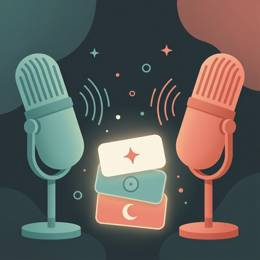
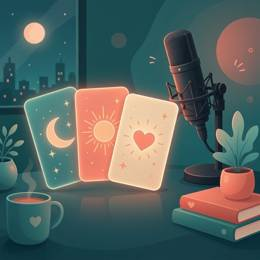
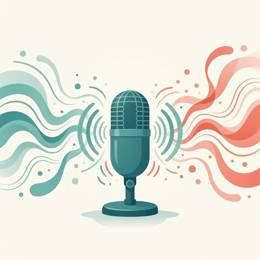
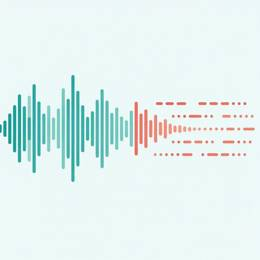
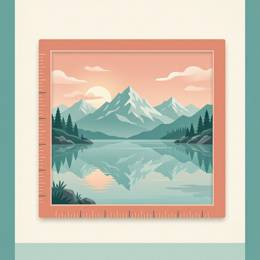
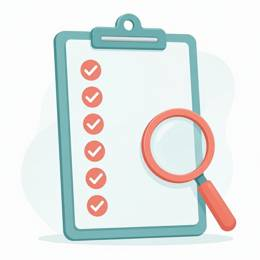

In [18]:
def thumbnail(path, width=260):
    with Image.open(path) as image:
        image.thumbnail((width, width))
        buffer = io.BytesIO()
        image.convert("RGB").save(buffer, format="JPEG", quality=70)
    return base64.b64encode(buffer.getvalue()).decode()


tiles = [("cover", "Cover (MAI-Image-2.6)")] + [(segment["id"], segment["title"]) for segment in EPISODE["segments"]]
cells = "".join(
    f'<figure style="margin:0;text-align:center"><img src="data:image/jpeg;base64,{thumbnail(OUT_DIR / "images" / f"{name}.png")}" '
    f'style="width:100%;border-radius:6px"><figcaption style="font-size:12px">{html.escape(label)}</figcaption></figure>'
    for name, label in tiles
)
display(HTML(f'<div style="display:grid;grid-template-columns:repeat(3,minmax(0,1fr));gap:12px;max-width:820px">{cells}</div>'))

## 13. Assemble the player

Everything is ready: audio, word timestamps, images, and the card excerpts for each line. The player template reads one JSON object and builds the page. It puts all episode text into the page with `textContent`, so nothing in the data can run as markup.

We write a folder with the page, the audio, the images, and a captions file. Then we check the page the way we would check any code we're about to share.

In [19]:
DISCLOSURE = "The voices in this episode are synthetic (MAI-Voice-2.1) and the pictures are generated (MAI-Image-2.6 and 2.6-Flash)."
PLAYER = OUT_DIR / "episode"
(PLAYER / "images").mkdir(parents=True, exist_ok=True)


def timestamp(seconds):
    hours, rest = divmod(seconds, 3600)
    minutes, secs = divmod(rest, 60)
    return f"{int(hours):02d}:{int(minutes):02d}:{secs:06.3f}"


lines_out, words_out, chapters_out, cues = [], [], [], ["WEBVTT", ""]
for segment in EPISODE["segments"]:
    info = segment_info[segment["id"]]
    chapters_out.append({"id": segment["id"], "title": segment["title"], "start": round(info["start"], 3), "end": round(info["end"], 3), "image": f"images/{segment['id']}.png"})
    for line in segment["lines"]:
        start, end = (info["start"] + t for t in info["line_spans"][line["id"]])
        lines_out.append({"id": line["id"], "hostName": HOSTS[line["host"]]["name"], "text": line["text"], "start": round(start, 3), "end": round(end, 3), "cites": [cite_info(c) for c in line["cites"]]})
        cues += [f"{timestamp(start)} --> {timestamp(end)}", f"{HOSTS[line['host']]['name']}: {line['text']}", ""]
    for word in biased_words[segment["id"]]:
        words_out.append({"w": word["w"], "start": round(info["start"] + word["start"], 3), "end": round(info["start"] + word["end"], 3)})

episode_data = {
    "title": EPISODE["title"], "subtitle": EPISODE["subtitle"], "disclosure": DISCLOSURE,
    "audio": "episode.wav", "cover": "images/cover.png",
    "chapters": chapters_out, "lines": lines_out, "words": words_out,
}

shutil.copy(episode_path, PLAYER / "episode.wav")
for name in ["cover"] + [segment["id"] for segment in EPISODE["segments"]]:
    shutil.copy(OUT_DIR / "images" / f"{name}.png", PLAYER / "images" / f"{name}.png")
(PLAYER / "captions.vtt").write_text("\n".join(cues), encoding="utf-8")
(PLAYER / "episode.json").write_text(json.dumps(episode_data, indent=1, ensure_ascii=False), encoding="utf-8")

template = (ASSETS / "player-template.html").read_text(encoding="utf-8")
payload = json.dumps(episode_data, ensure_ascii=False).replace("</", "<\\/")   # keep text from closing the script tag
(PLAYER / "index.html").write_text(template.replace("__EPISODE_DATA__", payload), encoding="utf-8")

print(f"Wrote {PLAYER}/index.html with {len(chapters_out)} chapters, {len(lines_out)} lines, {len(words_out)} timed words")
print(f"Wrote {PLAYER}/captions.vtt")
print(f"To watch it:  python -m http.server 8000 --directory {PLAYER}   then open http://localhost:8000")

Wrote output/episode/index.html with 5 chapters, 31 lines, 539 timed words
Wrote output/episode/captions.vtt
To watch it:  python -m http.server 8000 --directory output/episode   then open http://localhost:8000


In [20]:
page = (PLAYER / "index.html").read_text(encoding="utf-8")
checks = {
    "loads nothing from the network": not re.search(r"<script[^>]+src=|fetch\(|XMLHttpRequest|import\(|<link[^>]+href=\"https?:", page),
    "never calls eval or Function": not re.search(r"\beval\(|new Function\(", page),
    "never uses innerHTML": "innerHTML" not in page,
    "puts episode text in with textContent": "textContent" in page,
}
for name, passed in checks.items():
    print(("pass  " if passed else "FAIL  ") + name)
assert all(checks.values()), "The page failed a check. Fix the template before sharing the episode."

pass  loads nothing from the network
pass  never calls eval or Function
pass  never uses innerHTML
pass  puts episode text in with textContent


In [21]:
audio_minutes = episode_seconds / 60
summary = pd.DataFrame([
    {"piece": "Narration, MAI-Voice-2.1", "amount": f"{total_chars:,} characters", "estimate, $": round(total_chars * VOICE_PRICE_PER_MILLION_CHARS / 1_000_000, 3)},
    {"piece": "Captions, MAI-Transcribe-2 (two passes)", "amount": f"{2 * audio_minutes:.1f} minutes", "estimate, $": round(2 * audio_minutes / 60 * 0.10, 4)},
    {"piece": "Images, MAI-Image-2.6 and Flash", "amount": f"{int(usage.num_output_tokens.sum()):,} output tokens", "estimate, $": "enter a rate above" if not RATE_PER_MILLION_OUTPUT_TOKENS else round(usage.num_output_tokens.sum() * RATE_PER_MILLION_OUTPUT_TOKENS / 1_000_000, 4)},
    {"piece": "Checks, Microsoft-Decision-1", "amount": f"{len(cited) + len(uncited) + 1} short requests", "estimate, $": "see the Pricing tab"},
])
print("Rates: Voice $22 per 1M characters and Transcribe $0.10 per hour (early-bird), from the cards on 2026-10-12.")
summary

Rates: Voice $22 per 1M characters and Transcribe $0.10 per hour (early-bird), from the cards on 2026-10-12.


,piece,amount,"estimate, $"
0,"Narration, MAI-Voice-2.1","3,052 characters",0.067
1,"Captions, MAI-Transcribe-2 (two passes)",7.9 minutes,0.0132
2,"Images, MAI-Image-2.6 and Flash","6,144 output tokens",enter a rate above
3,"Checks, Microsoft-Decision-1",32 short requests,see the Pricing tab


## 14. Your Turn to Explore

1. Add a fourth card. Put excerpts for another model, such as Microsoft-Decision-1, into `assets/card-excerpts.json`, add a segment to `assets/episode-script.json` that cites them, and rerun. Does the gate in section 6 agree with your lines?
2. Tamper with a different line in section 6.1, for example a limit or a date, and see which changes the gate catches. Which ones does it miss?
3. Draft a segment with a chat model such as GPT-6 Sol, using only the card excerpts as source, and run the gate on its lines before you voice them.

In [22]:
# Your experiments here

## 15. Summary

We used three MAI models and Microsoft-Decision-1 to:

- Read three real model cards, check that every excerpt was still on its card, and cite them line by line in a script
- Check each claim against its excerpt before paying for speech, and watch the gate catch a tampered price
- Voice two hosts with MAI-Voice-2.1 and keep every clip under the card's per-generation limit
- Transcribe with MAI-Transcribe-2, find that model names were misspelled, and fix it with a phrase list
- Draw a cover and five chapter images, and read the token counts the responses report
- Assemble a player where each line shows the card text it came from

When a model's card gives a number or a limit, we can test it. When the card is silent, as the image card is on limitations, the gap is where our own tests go. Notebook 02 reuses the same pattern on release announcements: [02-release-notes-radio.ipynb](02-release-notes-radio.ipynb). For background, see the [model cards primer](../../../docs/primers/model-cards.md) and the [Audio / Speech primer](../../../docs/primers/audio-speech.md).

## 16. References

- [MAI-Voice-2.1 model card](https://ai.azure.com/catalog/models/MAI-Voice-2.1) - limits, price, voice cloning access, and responsible AI notes
- [MAI-Transcribe-2 model card](https://ai.azure.com/catalog/models/MAI-Transcribe-2) - capabilities, formats, and early-bird pricing
- [MAI-Image-2.6-Flash model card](https://ai.azure.com/catalog/models/MAI-Image-2.6-Flash) - output limits, languages, lifecycle, and what the card doesn't say
- [MAI voices in Azure Speech](https://learn.microsoft.com/azure/ai-services/speech-service/mai-voices) - prebuilt voices, styles, and gated features
- [Deploy and use Microsoft-Decision-1](https://learn.microsoft.com/azure/foundry/foundry-models/how-to/use-foundry-models-microsoft-decision) - the checker's request and response shapes
- [Model cards primer](../../../docs/primers/model-cards.md) - how to read a card before relying on a model